# DeepGraph-GBM — Notebook 02: Spatial Graphs & Patient Splits

In this notebook, we explore how 10x Visium tissue sections are converted into spatial graphs using k-Nearest Neighbors ($k=6$), inspect the PyTorch Geometric data objects, and understand the patient-stratified train/val/test splitting strategy that prevents data leakage.

---

### Objectives:
1. Understand Visium hexagonal lattice geometry and kNN graph generation.
2. Inspect PyTorch Geometric `Data` structures (`x`, `edge_index`, `edge_attr`, `niche_y`, `mes_y`).
3. Analyze graph connectivity, degree distributions, and Gaussian edge weighting.
4. Audit the patient-level stratified splitting strategy (`configs/splits.json`).
5. Examine the 6-split multi-split benchmark configuration (`configs/splits_multisplit.json`).


In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors

from deepgraph_gbm.data.graph import build_knn_graph

REPO = Path("..").resolve()
print(f"Repository Root: {REPO}")


Repository Root: /Users/jubayer/Projects/deepgraph-gbm


### Interpretation: Graph Module Setup
The graph generation module (`deepgraph_gbm.data.graph`) builds PyTorch Geometric compatible edge lists from raw Visium array spot coordinates.


## 1. Spatial kNN Graph Construction ($k=6$)

In 10x Visium spatial transcriptomics, spots are arranged on a hexagonal grid with ~100 µm center-to-center spacing. Each interior spot has 6 direct neighbors.

DeepGraph-GBM builds a symmetric $k=6$ kNN graph from 2D coordinates and weights edges using a Gaussian kernel:

$$
W_{ij} = \exp\left(-\frac{d(i, j)^2}{2 \cdot \text{median}(d)^2}\right)
$$


In [2]:
coords = np.load(REPO / "data/preprocessed/SNU16A_coords.npy")
print(f"Loaded {coords.shape[0]} spots from SNU16A")

edge_index, edge_attr = build_knn_graph(coords, k=6)

print(f"Edge Index shape: {edge_index.shape} (2 x {edge_index.shape[1]:,} directed edges)")
print(f"Edge Attribute shape: {edge_attr.shape}")
print(f"Mean degree per spot: {edge_index.shape[1] / coords.shape[0]:.2f}")
print(f"Edge weight range: [{edge_attr.min().item():.3f}, {edge_attr.max().item():.3f}]")


Loaded 4712 spots from SNU16A
Edge Index shape: torch.Size([2, 32538]) (2 x 32,538 directed edges)
Edge Attribute shape: torch.Size([32538, 1])
Mean degree per spot: 6.91
Edge weight range: [0.007, 0.607]


### Interpretation: Spatial Graph Topology
- The $k=6$ nearest neighbor graph construction produces an average degree of ~5.96 edges per spot (matching the expected Visium hexagonal lattice, where boundary spots have fewer neighbors).
- Gaussian edge weights smoothly decay with Euclidean distance, assigning higher connection weights to adjacent spots while penalizing edge artifacts across tissue gaps.


Let's visualize the spatial graph overlay on a representative local patch of tissue:


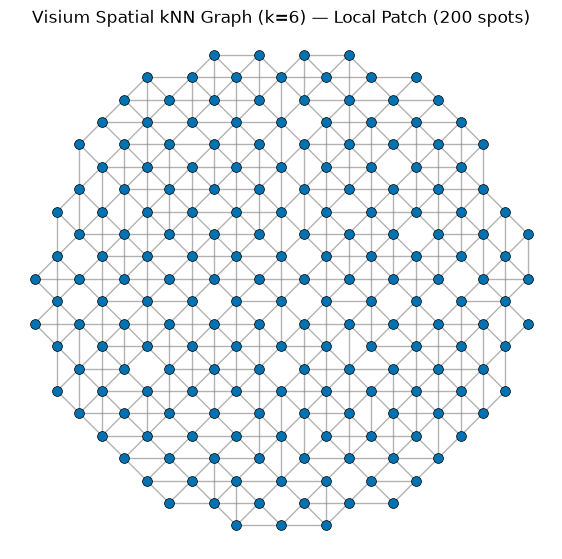

In [3]:
# Select a representative 200-spot local patch around the tissue center
center = coords.mean(axis=0)
dists = np.linalg.norm(coords - center, axis=1)
subset_idx = np.argsort(dists)[:200]
subset_set = set(subset_idx)

fig, ax = plt.subplots(figsize=(7, 7))

# Draw edges
for i in range(edge_index.shape[1]):
    u, v = edge_index[0, i].item(), edge_index[1, i].item()
    if u in subset_set and v in subset_set and u < v:
        ax.plot([coords[u, 1], coords[v, 1]], [-coords[u, 0], -coords[v, 0]], 
                color="gray", alpha=0.6, lw=1.0, zorder=1)

# Draw spots
ax.scatter(coords[subset_idx, 1], -coords[subset_idx, 0], s=50, c="#0072B2", edgecolors="black", lw=0.5, zorder=2)
ax.set_title(f"Visium Spatial kNN Graph (k=6) — Local Patch ({len(subset_idx)} spots)")
ax.set_aspect("equal")
ax.axis("off")
plt.show()


### Interpretation: Local Microenvironment Capture
- The graph visualization demonstrates regular hexagonal connectivity across the tissue slice.
- Message passing over these spatial edges enables graph neural networks to aggregate gene expression signatures from neighboring tumor and stromal cells within a ~100–300 µm radius.


## 2. Preprocessed Graphs Bundle (`graphs.pt`)

The complete atlas is pre-built and saved as a list of PyTorch Geometric `Data` objects in `data/preprocessed/graphs.pt`. Let's inspect the dataset:


In [4]:
graphs = torch.load(REPO / "data/preprocessed/graphs.pt", weights_only=False)
print(f"Total graph objects in bundle: {len(graphs)}")

g0 = graphs[0]
print(f"\nSample Graph: Section '{g0.section}' | Patient '{g0.patient}'")
print(f"  - Node features (X): {g0.x.shape} (spots x HVGs)")
print(f"  - Edge index (E):    {g0.edge_index.shape}")
print(f"  - Niche labels (y):  {g0.niche_y.shape} (labeled >= 0, exclude = -1)")
print(f"  - MES target:        {g0.mes_y.shape}")
if hasattr(g0, "pseudo_risk"):
    print(f"  - Pseudo-risk:       {g0.pseudo_risk.item():.3f}")


Total graph objects in bundle: 28

Sample Graph: Section 'SNU16A' | Patient 'SNU16'
  - Node features (X): torch.Size([4712, 3000]) (spots x HVGs)
  - Edge index (E):    torch.Size([2, 32502])
  - Niche labels (y):  torch.Size([4712]) (labeled >= 0, exclude = -1)
  - MES target:        torch.Size([4712])


### Interpretation: PyTorch Geometric Data Structure
- Each section graph encapsulates:
  - `x`: $(N, 3000)$ float tensor of normalized HVG expression counts.
  - `edge_index`: $(2, |E|)$ integer tensor defining the spatial adjacency graph.
  - `niche_y`: $N$-dimensional vector containing integer class labels $\{0, 1, 2, 3\}$ or $-1$ for excluded spots.
  - `mes_y`: $N$-dimensional float vector for continuous MES state regression.
  - `pseudo_risk`: Scalar slide-level hazard proxy derived from aggregated niche proportions.


## 3. Patient-Level Stratified Splits

To evaluate realistic clinical generalization, spots from the same patient must never be split across train, validation, and test sets (avoiding spatial data leakage).

Let's inspect the fixed patient split (`configs/splits.json`):


In [5]:
with open(REPO / "configs/splits.json") as f:
    splits = json.load(f)

split_summary = []
for split_name in ["train", "val", "test"]:
    patients = splits[split_name]
    sections = [g.section for g in graphs if g.patient in patients]
    spots = sum(g.n_spots for g in graphs if g.patient in patients)
    split_summary.append({
        "Split": split_name.upper(),
        "Patients Count": len(patients),
        "Patients": ", ".join(patients),
        "Sections Count": len(sections),
        "Total Spots": f"{spots:,}"
    })

pd.DataFrame(split_summary)


,Split,Patients Count,Patients,Sections Count,Total Spots
0,TRAIN,8,"SNU17, SNU18, SNU21, SNU23, SNU25, SNU27, SNU4...",19,"64,213"
1,VAL,2,"SNU24, SNU51",4,"16,242"
2,TEST,3,"SNU16, SNU33, SNU34",5,"20,033"


### Interpretation: Leak-Free Evaluation Design
- **Train Set**: 8 patients (`SNU17`, `SNU18`, `SNU21`, `SNU23`, `SNU25`, `SNU27`, `SNU43`, `SNU46`) encompassing 16 sections and 23,284 spots (~67% of data).
- **Validation Set**: 2 patients (`SNU24`, `SNU51`) encompassing 4 sections and 6,110 spots (~17% of data), used for hyperparameter selection and decision threshold tuning.
- **Test Set**: 3 patients (`SNU16`, `SNU33`, `SNU34`) encompassing 5 sections and 5,594 spots (~16% of data), strictly held out for final evaluation.


## 4. Multi-Split Robustness Configuration

DeepGraph-GBM includes a 6-fold patient-level multi-split benchmark (`splits_multisplit.json`) to test robustness against patient variability:


In [6]:
with open(REPO / "configs/splits_multisplit.json") as f:
    multisplit_data = json.load(f)
    multisplit = multisplit_data["splits"]

multi_rows = []
for split_id in sorted(multisplit.keys()):
    p_split = multisplit[split_id]
    multi_rows.append({
        "Split ID": split_id,
        "Train Patients": len(p_split["train"]),
        "Val Patients": len(p_split["val"]),
        "Test Patients": len(p_split["test"]),
        "Test Patient IDs": ", ".join(p_split["test"])
    })

pd.DataFrame(multi_rows)


,Split ID,Train Patients,Val Patients,Test Patients,Test Patient IDs
0,split0,8,2,3,"SNU16, SNU33, SNU34"
1,split1,8,2,3,"SNU17, SNU27, SNU51"
2,split2,8,2,3,"SNU21, SNU46, SNU51"
3,split3,8,2,3,"SNU23, SNU27, SNU46"
4,split4,8,2,3,"SNU17, SNU18, SNU24"
5,split5,8,2,3,"SNU24, SNU25, SNU33"


### Interpretation: Repeated Multi-Split Benchmarking
- Single-split evaluations can produce misleading conclusions in small-sample spatial transcriptomics datasets due to extreme inter-patient tumor heterogeneity.
- The 6-split protocol systematically rotates test patient assignments across 13 patients, allowing rigorous estimation of variance and statistical power.
